In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.cm as cm
import matplotlib.ticker as ticker
import os
import seaborn as sns
import matplotlib.cm as cm
from scipy.signal import find_peaks
from time import sleep
from scipy.optimize import curve_fit
from matplotlib.ticker import MultipleLocator

# Averaging dB vs Averaging Linear

First we want to simulate the background S curve.
We can take the comsol simulation of the S params we obtained for the waveguide.

Then we simulate an FMR curve onto that.
We can do this by making a lorentz curve based on the parameters we've measured previously then adding it to the curve

We can then take a random normal distribution based on the specification of $\pm 1.5$ dB 

Then average them in linear and in logarithmic to see what would happen

In [159]:
def dB_to_linear(y_data):
    '''takes y-data in dB and returns it in linear
    Assuming the conversion 1dB = 10log10(linear)'''

    return 10**(y_data/10)

    
def log_from_linear(power):
   '''takes "power" in linear units and returns in dB
   Assuming conversion 1dB = 10 log10 (linear)'''
   
   dB = 10*np.log10(power)

   return dB

def lorentzian(x, amplitude, center, gamma, offset):
    return offset + (amplitude * gamma**2 / ((x - center)**2 + gamma**2))

In [62]:
'''import simulated S21 data'''


def import_data(file_path):

    if 'calibration' in file_path:

        headers_used = ['Stimulus(Hz)', 'S21(dB)', 'S11(dB)']
    
    else:
        headers_used = ['Stimulus(Hz)', 'S11(dB)', 'S21(dB)']


    data = pd.read_csv(file_path, comment='!', sep=',', names=headers_used, header=None)

    data = data.rename(columns=lambda x: x.strip())
    headers = data.columns.tolist()
    return data, headers


calibration_data_path = 'C:/Users/nicoe/OneDrive - Imperial College London/Documents/A Univeristy/Year 4/Masters Project/Results/Experiments/VNA_FMR/calibration/data/20-02-2026/S_calibration_PY_12-06-32.csv'

background , bg_headers= import_data(calibration_data_path)

freqs = list(np.linspace(300e3, 17e9, 4001))

# print(freqs)

background['Stimulus(Hz)'] = freqs

# taper_cpw, headers_cpw = import_data("C:/Users/nicoe/OneDrive - Imperial College London/Documents/A Univeristy/Year 4/Masters Project/Data Analysis/taper/S-parameters-taper.txt")

print(background)



      Stimulus(Hz)    S21(dB)    S11(dB)
0     3.000000e+05  -0.092053 -26.664958
1     4.549925e+06  -0.053655 -32.134497
2     8.799850e+06  -0.085164 -31.357585
3     1.304978e+07  -0.144299 -31.227032
4     1.729970e+07  -0.169817 -31.213751
...            ...        ...        ...
3996  1.698300e+10 -24.143925  -5.131678
3997  1.698725e+10 -23.816948  -5.357647
3998  1.699150e+10 -23.493152  -5.598085
3999  1.699575e+10 -23.171884  -5.855100
4000  1.700000e+10 -22.873007  -6.121811

[4001 rows x 3 columns]


In [143]:
'''For the lorentzian we can use normalised amplitude of around 0.4 and FWHM of 2.339e+08 
lorentzian function takes:
x, amplitude, center, fwhm, offset'''



amplitude = -0.2*(background['S21(dB)'].max()-background['S21(dB)'].min())

center = 6e9 #GHz

fwhm = 2.339e8/2 #GHz

# offset = (background['S21(dB)'].loc[abs(background['Stimulus(Hz)']-center)<=5e7]).max()

offset = background['S21(dB)'].max()

# print(offset)

span = 750

x_vals = background['Stimulus(Hz)'].iloc[1412-span:1412+span].values

# print(x_vals)

lorentz = lorentzian(x_vals, amplitude, center, fwhm, offset)

df_simulated = background[['Stimulus(Hz)', 'S21(dB)']].copy()

df_simulated['S21(dB)'].iloc[1412-span:1412+span] = background['S21(dB)'].iloc[1412-span:1412+span].values + lorentz

print(df_simulated)

df_dip = pd.DataFrame({
    'Stimulus(Hz)' : x_vals,
    'vals' : lorentz
})



      Stimulus(Hz)    S21(dB)
0     3.000000e+05  -0.092053
1     4.549925e+06  -0.053655
2     8.799850e+06  -0.085164
3     1.304978e+07  -0.144299
4     1.729970e+07  -0.169817
...            ...        ...
3996  1.698300e+10 -24.143925
3997  1.698725e+10 -23.816948
3998  1.699150e+10 -23.493152
3999  1.699575e+10 -23.171884
4000  1.700000e+10 -22.873007

[4001 rows x 2 columns]


C:\Users\nicoe\AppData\Local\Temp\ipykernel_69200\2852229498.py:29: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df_simulated['S21(dB)'].iloc[1412-span:1412+span] = background['S21(dB)'].iloc[1412-span:1412+span].values + lorentz


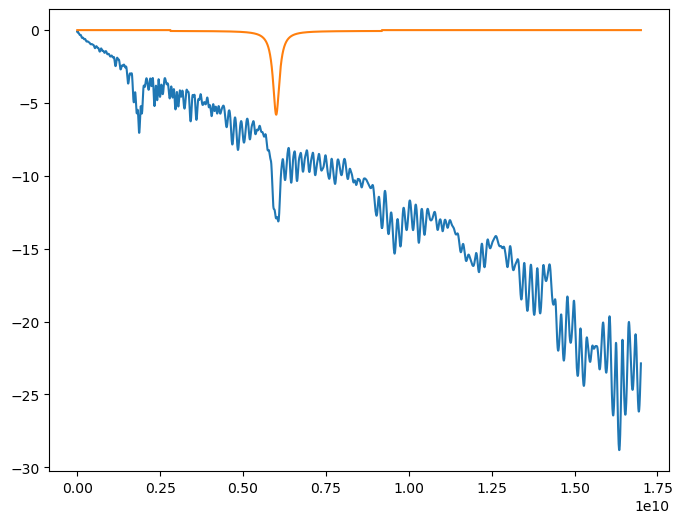

In [144]:

# df_dip.set_index('Stimulus(Hz)', inplace=True)
# background.set_index('Stimulus(Hz)', inplace=True)

fig, ax = plt.subplots(figsize = (8,6))

# ax.plot(x_vals, lorentz)

ax.plot(df_simulated['Stimulus(Hz)'], df_simulated['S21(dB)'])

ax.plot(df_simulated['Stimulus(Hz)'], df_simulated['S21(dB)'].sub(background['S21(dB)']))


In [145]:
'''add normal variation of measurements in dB to simulated data'''


df_simulated['noise'] = np.random.normal(0, 0.1, len(df_simulated))

df_simulated['noise_S21(dB)'] = df_simulated['S21(dB)']+df_simulated['noise']



print(df_simulated)

      Stimulus(Hz)    S21(dB)     noise  noise_S21(dB)
0     3.000000e+05  -0.092053 -0.149115      -0.241168
1     4.549925e+06  -0.053655  0.188649       0.134994
2     8.799850e+06  -0.085164 -0.226421      -0.311585
3     1.304978e+07  -0.144299 -0.076949      -0.221248
4     1.729970e+07  -0.169817  0.064752      -0.105065
...            ...        ...       ...            ...
3996  1.698300e+10 -24.143925 -0.109048     -24.252973
3997  1.698725e+10 -23.816948  0.078429     -23.738519
3998  1.699150e+10 -23.493152  0.120749     -23.372403
3999  1.699575e+10 -23.171884  0.170788     -23.001096
4000  1.700000e+10 -22.873007  0.012988     -22.860019

[4001 rows x 4 columns]


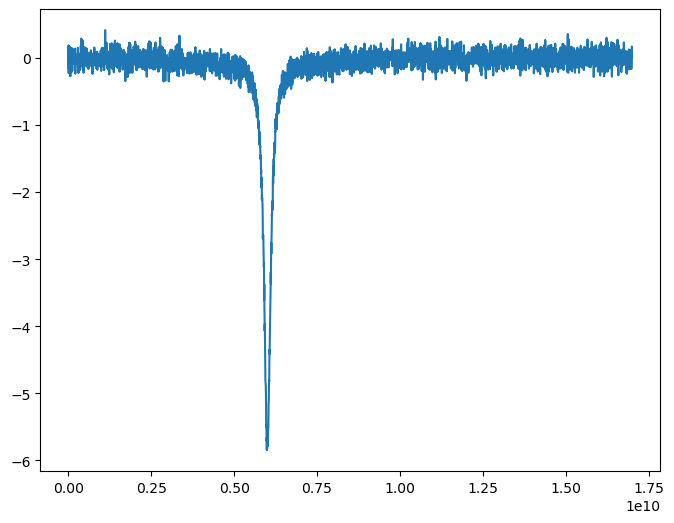

In [146]:

fig, ax = plt.subplots(figsize = (8,6))

# ax.plot(x_vals, lorentz)


# ax.plot(df_simulated['Stimulus(Hz)'], df_simulated['noise_S21(dB)'])
# ax.plot(df_simulated['Stimulus(Hz)'], df_simulated['S21(dB)'])


ax.plot(df_simulated['Stimulus(Hz)'], df_simulated['noise_S21(dB)'].sub(background['S21(dB)']))


In [174]:
true_signal = df_simulated[['Stimulus(Hz)', 'S21(dB)']].copy()

random_variation_signal = df_simulated[['Stimulus(Hz)', 'S21(dB)']].copy()



measurements = 5

for i in range(measurements):
    noise = np.random.normal(-0.1, 1.5, len(df_simulated))
    random_variation_signal[f'signal_{i}'] = true_signal['S21(dB)'] + noise

print(random_variation_signal)


      Stimulus(Hz)    S21(dB)   signal_0   signal_1   signal_2   signal_3  \
0     3.000000e+05  -0.092053   0.661026  -0.147076  -0.414822  -0.085332   
1     4.549925e+06  -0.053655  -0.279572   1.890344   0.085298  -0.862288   
2     8.799850e+06  -0.085164  -1.467245  -3.426684  -0.870298  -0.641774   
3     1.304978e+07  -0.144299  -1.147615  -1.621290  -3.229087  -1.756588   
4     1.729970e+07  -0.169817   1.694069  -1.075748  -0.290826   0.122903   
...            ...        ...        ...        ...        ...        ...   
3996  1.698300e+10 -24.143925 -24.720215 -20.000372 -25.072558 -22.570779   
3997  1.698725e+10 -23.816948 -23.267411 -23.771618 -23.919565 -22.122677   
3998  1.699150e+10 -23.493152 -22.193257 -24.102252 -25.460293 -26.405753   
3999  1.699575e+10 -23.171884 -20.370791 -22.818463 -21.968609 -22.149453   
4000  1.700000e+10 -22.873007 -20.113528 -24.966732 -23.543810 -24.848721   

       signal_4  
0     -1.492557  
1     -0.137144  
2     -0.824510  
3  

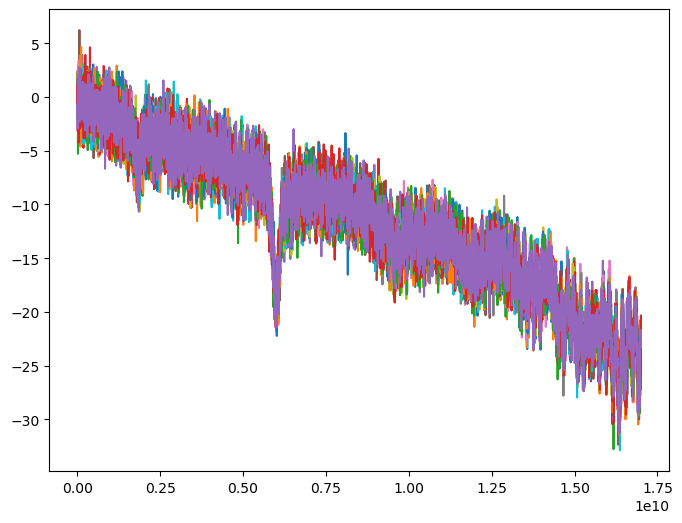

In [133]:
fig, ax = plt.subplots(figsize = (8,6))

# ax.plot(x_vals, lorentz)


# ax.plot(df_simulated['Stimulus(Hz)'], df_simulated['noise_S21(dB)'])
# ax.plot(df_simulated['Stimulus(Hz)'], df_simulated['S21(dB)'])

for i, col in enumerate(random_variation_signal.columns):

    if 'signal' in col:
        ax.plot(random_variation_signal['Stimulus(Hz)'], random_variation_signal[f'{col}']) #.sub(background['S21(dB)'])

    else:
        pass


In [175]:
df_noisy_linear = random_variation_signal.copy()

df_noisy_linear.iloc[:,-measurements:] = df_noisy_linear.iloc[:,-measurements:].map(dB_to_linear)

df_noisy_linear['mean'] = df_noisy_linear.iloc[:, -measurements:].mean(axis=1)

print(df_noisy_linear)

      Stimulus(Hz)    S21(dB)  signal_0  signal_1  signal_2  signal_3  \
0     3.000000e+05  -0.092053  1.164401  0.966702  0.908903  0.980543   
1     4.549925e+06  -0.053655  0.937654  1.545377  1.019835  0.819919   
2     8.799850e+06  -0.085164  0.713305  0.454288  0.818409  0.862626   
3     1.304978e+07  -0.144299  0.767783  0.688448  0.475435  0.667331   
4     1.729970e+07  -0.169817  1.477090  0.780594  0.935228  1.028704   
...            ...        ...       ...       ...       ...       ...   
3996  1.698300e+10 -24.143925  0.003373  0.009999  0.003110  0.005533   
3997  1.698725e+10 -23.816948  0.004713  0.004196  0.004055  0.006134   
3998  1.699150e+10 -23.493152  0.006035  0.003888  0.002844  0.002288   
3999  1.699575e+10 -23.171884  0.009182  0.005226  0.006355  0.006096   
4000  1.700000e+10 -22.873007  0.009742  0.003187  0.004422  0.003274   

      signal_4      mean  
0     0.709160  0.945942  
1     0.968915  1.058340  
2     0.827083  0.735142  
3     0.979977 

In [176]:
'''averaging in dB'''


df_noisy = random_variation_signal.copy()

df_noisy['mean'] =  df_noisy.iloc[:, -measurements:].mean(axis=1)

# df_noisy = random_variation_signal.iloc[:,-measurements:].copy()

# dB_average = 

# print(df_noisy)


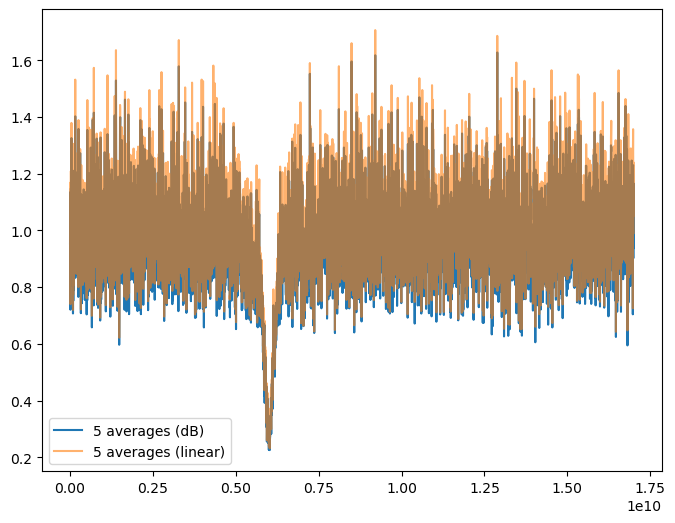

In [187]:
fig, ax = plt.subplots(figsize = (8,6))

ax.plot(df_noisy['Stimulus(Hz)'], (df_noisy['mean'].sub(background['S21(dB)'])).apply(dB_to_linear), label = f'{measurements} averages (dB)')

ax.plot(df_noisy_linear['Stimulus(Hz)'], (df_noisy_linear['mean'].apply(log_from_linear).sub(background['S21(dB)'])).apply(dB_to_linear), label = f'{measurements} averages (linear)', alpha = 0.6)

# ax.plot(df_simulated['Stimulus(Hz)'], df_simulated['S21(dB)'].sub(background['S21(dB)']), label = 'true signal')

ax.legend()
